**Human Movement Intelligence | Biomechanical Load Estimation | Presented by: Reza Saadatyar (2026)**

**04 | Governed IMU–FE Dataset Construction and Participant-Independent Splits**

![Governed source pairing and participant-disjoint data workflow](../../images/04_consolidated_workflow.svg)

**Research question:** Can the original 40-participant Essex dataset be transformed into a reproducible source-identified IMU–FE regression input dataset, with exact original time-coordinate pairing, justified exclusions and a fixed participant-disjoint evaluation protocol?

**Prior verified evidence:** [Notebook 01](01_original_dataset_audit_and_trial_registry.ipynb) establishes the source identities and fingerprints; [Notebook 02](02_matlab_object_decoding_and_numeric_recovery.ipynb) records tested MATLAB decoding; [Notebook 03](03_full_cohort_numeric_and_temporal_validation.ipynb) establishes 1,729 exactly mapped numerical FE trials and 168 original FE-empty records.

**Published target semantics:** The original [Scientific Data article](https://doi.org/10.1038/s41597-026-07429-3), Table 3, describes first and third principal femoral-neck strains `e1` and `e3` as **unitless** FE-model outputs. This is publisher-reported source metadata, not independently calibrated clinical measurement.

**Governance:** Re-read only the original source MATLAB files acquired through the checksum-pinned public GitHub Release and the saved CSV/JSON artefacts in `biomechanical_load_estimation/output/`. Never read any earlier `.ipynb` results. Preserve all 1,897 trial identities and flag 168 original FE-empty records as exclusions, not imputed targets.

**Exact numerical pairing:** Preserve 101×42 original IMU values and the eleven 42-channel IMU values at the eleven source-verified FE time positions, paired with 11×2 original FE values. No interpolation, resampling, target conversion or invented FE signal is permitted.

**Leakage control:** Fix subject-ID-only train/validation/test assignments before model development. Three participants without eligible FE remain excluded, and the 37 others are split 29/4/4. Compute descriptive channel statistics **only from training subjects**; retain original arrays unchanged.

**Public repository policy:** Commit small `04_*` CSV/JSON/PNG reproducibility artefacts in the flat `output/` folder. Build the full numeric paired arrays into ignored `data/processed/` locally during each fresh Colab runtime; never commit the large derived dataset.

**Boundary:** No predictive model fitting, performance claims, independent FE physics calibration, clinical validation or test-set selection based on target performance.

**Recorded execution:** All eleven code cells have saved executions without recorded errors. The stage-04 dataset-and-split Quality Gate reports **PASSED**, and all fourteen `04_*` CSV/JSON/PNG evidence files are committed. No regression-model fitting was performed.


**00. Colab Repository Setup**


In [1]:
# ======================== 00. Colab Repository Setup =========================

from pathlib import Path
import subprocess
import sys

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_branch = "main"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(["git", "clone", "--branch", repo_branch,
                    repo_url, str(repo_path)], check=True)
elif not (repo_path / "python_modules/core/repository_sync.py").is_file():
    cmd = ["git", "-C", str(repo_path)]
    origin = subprocess.check_output(cmd + ["remote", "get-url", "origin"],
                                     text=True).strip()
    if origin.rstrip("/").removesuffix(".git") != repo_url.removesuffix(".git"):
        raise RuntimeError("Existing repository has an unexpected origin.")
    branch = subprocess.check_output(cmd + ["branch", "--show-current"],
                                     text=True).strip()
    dirty = subprocess.check_output(cmd + ["status", "--porcelain"],
                                    text=True).strip()
    if branch != repo_branch or dirty:
        raise RuntimeError("Cannot migrate a modified or different branch.")
    subprocess.run(cmd + ["pull", "--ff-only", "origin", repo_branch], check=True)

sys.path.insert(0, str(repo_path))
from python_modules.core.repository_sync import safe_sync_repository

repo_path = safe_sync_repository(repo_url, repo_branch, parent=repo_path.parent)
%cd {repo_path}


Repository CLONED | branch=main | commit=106b7709ec05
/content/human-movement-intelligence


**01. Imports and Research Environment**

Use shared original-source and reusable paired-data modules with separate paths for public evidence and ignored numerical arrays.


In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("biomechanical_load_estimation")

# -------------------- 2. Standard Library and Environment --------------------
import json
from importlib.metadata import version
from pathlib import Path

# ------------------ 3. Scientific Computing and Data Frames ------------------
import numpy as np
import pandas as pd

# ------------------- 4. Research Visualisation and Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
plot_style(font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5, label_weight="normal",
    tick_size=11, legend_size=10, figure_dpi=100,
    figure_size=(9, 4))

# ----------- 5. Shared Original and Paired-Data Research Utilities -----------
from core.output_download import download_outputs_from_colab
from essex_figshare import (
    ARTICLE_ID, ARTICLE_VERSION, ensure_pinned_matlab_archive,
    inspect_matlab_archive, extract_matlab_files,
)
from essex_numeric_recovery import check_record_registry
from essex_paired_dataset import (
    build_paired_arrays, fixed_subject_splits,
    training_channel_stats, paired_source_digest, save_ignored_cache,
)
from essex_timebase_audit import EXPECTED_CHANNELS

# --------------- 6. Original Data and Public Research Outputs ----------------
study_dir = root / "biomechanical_load_estimation"
raw_dir = root / "data" / "raw" / "essex_femoral_neck_loading"
mat_dir = raw_dir / "matlab_records"
processed_dir = root / "data" / "processed" / "essex_femoral_neck_loading"
output_dir = study_dir / "output"
raw_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)
assert output_dir.name == "output"
print("Public research outputs:", output_dir)
print("Git-ignored numerical data cache:", processed_dir)


Public research outputs: /content/human-movement-intelligence/biomechanical_load_estimation/output
Git-ignored numerical data cache: /content/human-movement-intelligence/data/processed/essex_femoral_neck_loading


**02. Pinned Original MATLAB Table Decoder**

Use the source-tested numerical MATLAB table reader; record the exact software version.


In [3]:
# ================= 02. Pinned Original MATLAB Table Decoder ==================

# -------------------- 1. Install Versioned MATLAB Reader ---------------------
%pip -q install --only-binary=:all: --no-deps "mat-io==1.0.1"
from matio import load_from_mat

# ----------------------------- 2. Verify Version -----------------------------
assert version("mat-io") == "1.0.1"
print("Verified source reader:", version("mat-io"))


Verified source reader: 1.0.1


**03. Upstream Integrity and Original Time Mapping**

Re-use only version-controlled CSV and JSON evidence from Notebooks 01–03. Independently verify the original source archive SHA256 before numerical pairing.


In [4]:
# ============= 03. Upstream Integrity and Original Time Mapping ==============

# ------------ 1. Verify the Three Executed Upstream Quality Gates ------------
path01 = output_dir / "01_consolidated_source_and_trial_quality_gate.json"
path02 = output_dir / "02_consolidated_decoding_quality_gate.json"
path03 = output_dir / "03_consolidated_numeric_temporal_quality_gate.json"
registry_path = output_dir / "01_original_record_registry.csv"
mapping_path = output_dir / "03_original_time_coordinate_mapping.csv"
required_paths = [path01, path02, path03, registry_path, mapping_path]
if not all(p.is_file() for p in required_paths):
    raise FileNotFoundError("Missing committed Notebook 01–03 evidence.")
q01 = json.loads(path01.read_text(encoding="utf-8"))
q02 = json.loads(path02.read_text(encoding="utf-8"))
q03 = json.loads(path03.read_text(encoding="utf-8"))
assert q01["source_article_id"] == ARTICLE_ID == 30225739
assert q01["version"] == ARTICLE_VERSION == 13
assert q01["source_and_trial_quality_gate"] == "PASSED"
assert q02["decoding_consistency_gate"] == "PASSED"
assert q03["full_numeric_temporal_quality_gate"] == "PASSED"
assert q01["archive_sha256"] == q02["source_sha256"]
assert q01["archive_sha256"] == q03["original_archive_sha256"]

# ------ 2. Load and Check Original Source Trial and FE Index Registries ------
registry = pd.read_csv(registry_path, dtype={
    "local_record_key": "string", "source_file": "string",
    "subject_id": "string", "task": "string",
    "updated_trial_id": "string", "fe_representation": "string",
})
mapping = pd.read_csv(mapping_path, dtype={
    "local_record_key": "string", "mapping_status": "string",
    "imu_position_indices": "string",
})
original = check_record_registry(registry, q01)
assert original["records"] == len(registry) == len(mapping) == 1897
assert original["participants"] == 40
assert mapping["mapping_status"].value_counts().to_dict() == {
    "EXACT_TIME_COORDINATE_MAPPING": 1729,
    "NO_SOURCE_FE_TARGET": 168,
}
print("Original 1897 trial identities and 1729 index maps: VERIFIED")

# ----- 3. Restore the Original Public and Checksum-Pinned MATLAB Archive -----
archive, original_hash = ensure_pinned_matlab_archive(raw_dir)
assert original_hash["sha256"] == q01["archive_sha256"]
inventory = inspect_matlab_archive(archive, expected_mat_files=40)
mat_files = extract_matlab_files(archive, mat_dir, inventory)
assert len(mat_files) == 40
print("Original participant MAT files:", len(mat_files))


Original 1897 trial identities and 1729 index maps: VERIFIED
MATLAB.zip downloaded and verified: GitHub Release.
Original participant MAT files: 40


**04. Build Source-Exact Numerical IMU–FE Pairs**

Pair all available target signals with the original observed time indices, preserve source identity, and account for every original FE-empty record.


In [5]:
# =============== 04. Build Source-Exact Numerical IMU–FE Pairs ===============

# ------------ 1. Construct Verified 101-Row and 11-Row IMU Inputs ------------
arrays, eligible, excluded = build_paired_arrays(
    load_from_mat, mat_dir, registry, mapping, q01
)
assert len(eligible) == 1729
assert len(excluded) == 168
assert arrays["X_full"].shape == (1729, 101, 42)
assert arrays["X_at_fe"].shape == (1729, 11, 42)
assert arrays["y_fe"].shape == (1729, 11, 2)
assert arrays["imu_positions"].shape == (1729, 11)
print("Original numeric IMU–FE pairs:", len(eligible))
print("Original source-empty FE exclusions:", len(excluded))

# ----------- 2. Save Complete Source Trial and Exclusion Evidence ------------
eligible.to_csv(
    output_dir / "04_eligible_trial_registry.csv", index=False
)
excluded.to_csv(
    output_dir / "04_excluded_trial_registry.csv", index=False
)
display(eligible.head())
display(excluded.head())


Original numeric IMU–FE pairs: 1729
Original source-empty FE exclusions: 168


,local_record_key,subject_id,source_file,local_record_index,task,updated_trial_id,time_mapping
0,subj04:0000,subj04,subj04.mat,0,CounterJumps,CounterJumpsMax1,EXACT_TIME_COORDINATE_MAPPING
1,subj04:0001,subj04,subj04.mat,1,CounterJumps,CounterJumpsMax2,EXACT_TIME_COORDINATE_MAPPING
2,subj04:0002,subj04,subj04.mat,2,CounterJumps,CounterJumpsMax3,EXACT_TIME_COORDINATE_MAPPING
3,subj04:0003,subj04,subj04.mat,3,CounterJumps,CounterJumpsMin1,EXACT_TIME_COORDINATE_MAPPING
4,subj04:0004,subj04,subj04.mat,4,CounterJumps,CounterJumpsMin2,EXACT_TIME_COORDINATE_MAPPING


,local_record_key,subject_id,task,source_file,reason,reader_class
0,subj06:0030,subj06,BilateralHopping,subj06.mat,SOURCE_FE_TARGET_EMPTY,MatlabCanonicalEmpty
1,subj06:0031,subj06,BilateralHopping,subj06.mat,SOURCE_FE_TARGET_EMPTY,MatlabCanonicalEmpty
2,subj06:0032,subj06,BilateralHopping,subj06.mat,SOURCE_FE_TARGET_EMPTY,MatlabCanonicalEmpty
3,subj06:0033,subj06,BilateralHopping,subj06.mat,SOURCE_FE_TARGET_EMPTY,MatlabCanonicalEmpty
4,subj06:0034,subj06,BilateralHopping,subj06.mat,SOURCE_FE_TARGET_EMPTY,MatlabCanonicalEmpty


**05. Source Semantics and Participant Eligibility**

Document source-published strain semantics, 42 unchanged IMU channels and the three participants with no eligible FE target.


In [6]:
# ============= 05. Source Semantics and Participant Eligibility ==============

# --------- 1. Quantify Eligibility for All 40 Original Participants ----------
participant_table = registry.groupby("subject_id").size().rename(
    "original_trials"
).reset_index()
participant_table = participant_table.join(
    eligible.groupby("subject_id").size().rename("eligible_pairs"),
    on="subject_id"
).join(
    excluded.groupby("subject_id").size().rename("empty_fe"),
    on="subject_id"
).fillna(0)
participant_table[["eligible_pairs", "empty_fe"]] = (
    participant_table[["eligible_pairs", "empty_fe"]].astype(int)
)
assert len(participant_table) == 40
assert participant_table["eligible_pairs"].sum() == 1729
assert participant_table["empty_fe"].sum() == 168
assert participant_table["eligible_pairs"].eq(0).sum() == 3
participant_table.to_csv(
    output_dir / "04_participant_eligibility.csv", index=False
)
display(participant_table)

# -------------- 2. Record Source Sensor and Target Definitions ---------------
channel_table = pd.DataFrame({
    "column_index": range(42), "source_column": EXPECTED_CHANNELS,
    "unit_conversion": "NONE",
})
target_table = pd.DataFrame({
    "source_column": ["e1", "e3"],
    "published_semantics": [
        "First principal femoral neck strain",
        "Third principal femoral neck strain",
    ],
    "published_unit": ["unitless", "unitless"],
    "independent_physical_calibration": [False, False],
})
channel_table.to_csv(
    output_dir / "04_channel_schema.csv", index=False
)
target_table.to_csv(
    output_dir / "04_target_schema.csv", index=False
)
display(target_table)


,subject_id,original_trials,eligible_pairs,empty_fe
0,subj04,48,48,0
1,subj05,48,48,0
2,subj06,48,39,9
3,subj08,48,39,9
4,subj09,42,42,0
5,subj10,48,48,0
6,subj11,40,34,6
7,subj12,47,47,0
8,subj13,48,48,0
9,subj14,42,42,0


,source_column,published_semantics,published_unit,independent_physical_calibration
0,e1,First principal femoral neck strain,unitless,False
1,e3,Third principal femoral neck strain,unitless,False


**06. Deterministic Leakage-Free Participant Splitting**

Freeze participant-only training/validation/test identities before any model fit. Save all trial membership and activity coverage, including three excluded participants.


In [7]:
# =========== 06. Deterministic Leakage-Free Participant Splitting ============

# --------- 1. Assign 37 Target-Bearing Participants before Modelling ---------
SPLIT_SEED = 2026
subjects, assignments, split_summary, activity = fixed_subject_splits(
    eligible, registry, seed=SPLIT_SEED
)
assert subjects["split"].value_counts().to_dict() == {
    "TRAIN": 29, "VALIDATION": 4, "TEST": 4,
    "EXCLUDED_NO_FE_TARGET": 3,
}
assert len(assignments) == 1729
display(split_summary)

# -------------- 2. Save Subject, Trial and Activity Partitions ---------------
subjects.to_csv(
    output_dir / "04_subject_split_assignments.csv", index=False
)
assignments.to_csv(
    output_dir / "04_trial_split_assignments.csv", index=False
)
split_summary.to_csv(
    output_dir / "04_split_trial_summary.csv", index=False
)
activity.to_csv(
    output_dir / "04_split_activity_coverage.csv", index=False
)
display(activity)


,split,participants,trials
0,TEST,4,183
1,TRAIN,29,1354
2,VALIDATION,4,192


,split,task,trials
0,TEST,BilateralHopping,27
1,TEST,CounterJumps,36
2,TEST,Running,36
3,TEST,SquatJumps,36
4,TEST,UnilateralHopping,36
5,TEST,Walking,12
6,TRAIN,BilateralHopping,237
7,TRAIN,CounterJumps,259
8,TRAIN,Running,261
9,TRAIN,SquatJumps,261


**07. Training-Only IMU Statistics**

Compute original channel means and standard deviations solely on training subjects; original numeric arrays remain untouched.


In [8]:
# ===================== 07. Training-Only IMU Statistics ======================

# ---------------- 1. Fit Statistics on Training Subjects Only ----------------
train_stats = training_channel_stats(arrays, assignments)
assert len(train_stats) == 42
assert train_stats["train_sample_rows"].min() > 0
train_stats.to_csv(
    output_dir / "04_training_channel_statistics.csv", index=False
)
display(train_stats.head(10))

# -------------- 2. Enforce Original Numeric Array Preservation ---------------
assert arrays["X_full"].dtype == np.float64
assert arrays["X_at_fe"].dtype == np.float64
assert arrays["y_fe"].dtype == np.float64
assert (np.diff(arrays["imu_positions"], axis=1) > 0).all()
assert np.isfinite(arrays["X_full"]).all()
assert np.isfinite(arrays["y_fe"]).all()
print("No time interpolation, imputation or early standardisation.")


,channel,train_mean,train_std,zero_std,safe_denominator,train_sample_rows
0,accel_x_PEL,12.727057,12.832166,False,12.832166,14894
1,accel_x_RTH,13.752150,12.846678,False,12.846678,14894
2,accel_x_LTH,13.426385,12.789260,False,12.789260,14894
3,accel_x_RSK,14.606504,15.685592,False,15.685592,14894
4,accel_x_LSK,9.955095,12.083439,False,12.083439,14894
5,accel_x_RFT,11.791044,20.510155,False,20.510155,14894
6,accel_x_LFT,11.578963,17.911740,False,17.911740,14894
7,accel_y_PEL,-0.066717,6.840652,False,6.840652,14894
8,accel_y_RTH,-2.584799,12.691066,False,12.691066,14894
9,accel_y_LTH,1.759749,10.996365,False,10.996365,14894


No time interpolation, imputation or early standardisation.


**08. Local Numerical Cache and Public Rebuild Manifest**

Save large pair arrays into an ignored local cache while keeping a lightweight, checked rebuild specification in public GitHub.


In [9]:
# =========== 08. Local Numerical Cache and Public Rebuild Manifest ===========

# -------- 1. Write Source-Verified Arrays outside the Git Repository ---------
cache_path = processed_dir / "essex_imu_fe_pairs_v13.npz"
cache_status = save_ignored_cache(cache_path, arrays, assignments)
pair_sha256 = paired_source_digest(arrays, assignments)
assert len(pair_sha256) == 64
print("Local source-paired numerical cache:", cache_path)
print("Cache status:", cache_status)

# -------- 2. Save the Reproducibility and Source-Fingerprint Manifest --------
manifest = {
    "source_dataset_id": ARTICLE_ID,
    "source_version": ARTICLE_VERSION,
    "original_archive_sha256": original_hash["sha256"],
    "original_source_records": len(registry),
    "source_numeric_pairs": len(eligible),
    "original_fe_missing": len(excluded),
    "feature_shape": list(arrays["X_full"].shape),
    "aligned_feature_shape": list(arrays["X_at_fe"].shape),
    "target_shape": list(arrays["y_fe"].shape),
    "time_indices_shape": list(arrays["imu_positions"].shape),
    "float_dtype": "float64",
    "fe_published_unit": "unitless",
    "independent_fe_calibration": False,
    "split_seed": SPLIT_SEED,
    "split_basis": "stable SHA256 of original subject identifier",
    "canonical_pair_sha256": pair_sha256,
    "cache_status": cache_status,
    "local_cache_path": (
        "data/processed/essex_femoral_neck_loading/"
        "essex_imu_fe_pairs_v13.npz"
    ),
    "binary_cache_committed": False,
    "model_training_performed": False,
    "clinical_validation_performed": False,
}
(output_dir / "04_local_dataset_build_manifest.json").write_text(
    json.dumps(manifest, indent=2) + "\n", encoding="utf-8"
)


Local source-paired numerical cache: /content/human-movement-intelligence/data/processed/essex_femoral_neck_loading/essex_imu_fe_pairs_v13.npz
Cache status: CREATED_LOCAL_ONLY


994

**09. Source Eligibility and Split Figures**

Show measured task coverage and partition counts without using any model scores or unverified FE unit transformations.


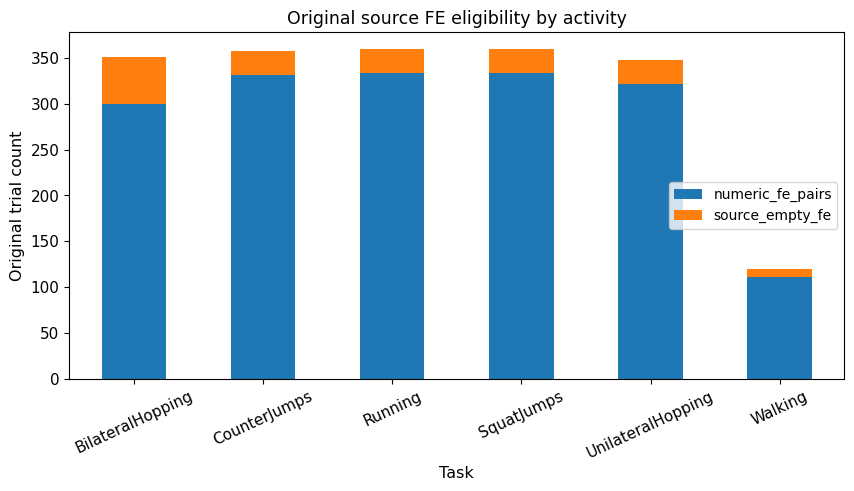

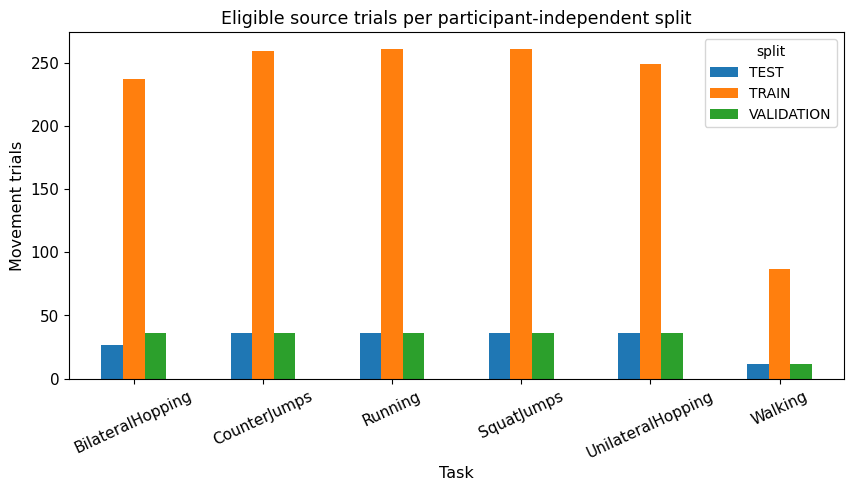

In [10]:
# ================= 09. Source Eligibility and Split Figures ==================

# ----------- 1. Original FE Eligibility across Movement Activities -----------
coverage = pd.concat([
    eligible["task"].value_counts().rename("numeric_fe_pairs"),
    excluded["task"].value_counts().rename("source_empty_fe"),
], axis=1).fillna(0).sort_index()
fig, ax = plt.subplots(figsize=(10, 4.5))
coverage.plot.bar(stacked=True, ax=ax)
ax.set_title("Original source FE eligibility by activity")
ax.set_ylabel("Original trial count")
ax.set_xlabel("Task")
ax.tick_params(axis="x", rotation=25)
save_figure(fig, output_dir / "04_eligibility_activity_coverage.png")
plt.show()

# ---------------- 2. Participant-Disjoint Partition Coverage -----------------
split_matrix = activity.pivot(
    index="task", columns="split", values="trials"
).fillna(0)
fig, ax = plt.subplots(figsize=(10, 4.5))
split_matrix.plot.bar(ax=ax)
ax.set_title("Eligible source trials per participant-independent split")
ax.set_ylabel("Movement trials")
ax.set_xlabel("Task")
ax.tick_params(axis="x", rotation=25)
save_figure(
    fig, output_dir / "04_participant_split_activity_coverage.png"
)
plt.show()


**10. Governed Pairing and Split Quality Gate**

Validate scientific input identities, 1,729 numeric pairs, 168 original FE-empty exclusions and all 14 stage-04 research output files.


In [11]:
# ================ 10. Governed Pairing and Split Quality Gate ================

# ------ 1. Verify All Original Trials and Source-Exact Numerical Arrays ------
assert len(registry) == len(eligible) + len(excluded) == 1897
assert len(eligible) == 1729 and len(excluded) == 168
assert eligible["local_record_key"].is_unique
assert excluded["local_record_key"].is_unique
assert set(eligible["local_record_key"]).isdisjoint(
    set(excluded["local_record_key"])
)
assert set(eligible["local_record_key"]) | set(
    excluded["local_record_key"]
) == set(registry["local_record_key"])
assert len(subjects) == 40 and len(assignments) == 1729
assert np.isfinite(arrays["y_fe"]).all()
assert paired_source_digest(arrays, assignments) == pair_sha256

# -------- 2. Verify Participant and Preprocessing Leakage Safeguards ---------
assert assignments.groupby("subject_id")["split"].nunique().eq(1).all()
for name in ("TRAIN", "VALIDATION", "TEST"):
    current = set(
        assignments.loc[assignments["split"] == name, "subject_id"]
    )
    for other in ("TRAIN", "VALIDATION", "TEST"):
        if name != other:
            other_set = set(
                assignments.loc[assignments["split"] == other, "subject_id"]
            )
            assert current.isdisjoint(other_set)
assert manifest["binary_cache_committed"] is False
assert manifest["model_training_performed"] is False

# --------- 3. Save an Honest Source-Pairing and Split Quality Record ---------
quality = {
    "source_article_id": ARTICLE_ID,
    "source_version": ARTICLE_VERSION,
    "original_sha256": original_hash["sha256"],
    "source_records": len(registry),
    "numerical_pairs": len(eligible),
    "original_source_empty_fe": len(excluded),
    "all_source_participants": 40,
    "participants_with_fe": 37,
    "partition_participants": subjects["split"].value_counts().to_dict(),
    "split_seed": SPLIT_SEED,
    "train_only_statistics": True,
    "canonical_pair_sha256": pair_sha256,
    "original_target_units_as_published": "unitless",
    "fe_unit_conversion_performed": False,
    "source_time_interpolation_performed": False,
    "stage04_quality_gate": "PASSED",
    "model_training_performed": False,
    "clinical_or_external_validation": False,
}
(output_dir / "04_dataset_and_split_quality_gate.json").write_text(
    json.dumps(quality, indent=2) + "\n", encoding="utf-8"
)
print("STAGE 04 | GOVERNED DATASET AND SPLIT QUALITY GATE: PASSED")

# ---------- 4. Check All Public Evidence and Download Stage Outputs ----------
expected = [
    "04_eligible_trial_registry.csv",
    "04_excluded_trial_registry.csv",
    "04_participant_eligibility.csv",
    "04_channel_schema.csv",
    "04_target_schema.csv",
    "04_subject_split_assignments.csv",
    "04_trial_split_assignments.csv",
    "04_split_trial_summary.csv",
    "04_split_activity_coverage.csv",
    "04_training_channel_statistics.csv",
    "04_local_dataset_build_manifest.json",
    "04_eligibility_activity_coverage.png",
    "04_participant_split_activity_coverage.png",
    "04_dataset_and_split_quality_gate.json",
]
missing = [name for name in expected if not (output_dir / name).is_file()]
if missing:
    raise FileNotFoundError("Missing stage 04 outputs: " + ", ".join(missing))
print("Validated stage 04 research outputs:", len(expected))
download_outputs_from_colab(
    folder="biomechanical_load_estimation/output", stage="04"
)


STAGE 04 | GOVERNED DATASET AND SPLIT QUALITY GATE: PASSED
Validated stage 04 research outputs: 14
------------------------------------------------------------------------
Notebook stage: 04
Files packaged: 14
  + 04_channel_schema.csv
  + 04_dataset_and_split_quality_gate.json
  + 04_eligibility_activity_coverage.png
  + 04_eligible_trial_registry.csv
  + 04_excluded_trial_registry.csv
  + 04_local_dataset_build_manifest.json
  + 04_participant_eligibility.csv
  + 04_participant_split_activity_coverage.png
  + 04_split_activity_coverage.csv
  + 04_split_trial_summary.csv
  + 04_subject_split_assignments.csv
  + 04_target_schema.csv
  + 04_training_channel_statistics.csv
  + 04_trial_split_assignments.csv
Download ZIP from Colab Contents: /content/biomechanical_load_estimation_Stage_04_Outputs.zip
GitHub Commit/Push performed: NO


**11. Scientific Interpretation and Next Research Boundary**

The new stage reconstructs original 101×42 IMU trials and eleven sample-aligned 42-channel sensor rows for every one of 1,729 eligible source records, paired with original 11×2 FE principal strain values. It protects original participant and trial identities and excludes precisely 168 source-empty FE targets without imputation.

The original publication identifies e1/e3 as unitless first and third principal femoral-neck FE strains; no independent FE calibration is performed here. The 37 eligible participants receive a fixed deterministic 29/4/4 participant-independent train/validation/test split; three fully FE-empty participants are recorded as excluded. Channel moments are estimated from training participants only, while all source numeric input arrays remain unchanged.

The binary paired dataset is a rebuildable local cache under Git-ignored data/processed/, not a GitHub research output. The public output/ folder receives only source registries, fixed split maps, training-only moments, provenance manifest, scientific figures and the Quality Gate.

**Next stage:** train transparent classical regression baselines using the frozen Training participants and restrict model selection and diagnostics to Training/Validation. Preserve all held-out Test participants for a separately approved, frozen final-evaluation protocol. Notebook 04 does not train or evaluate any regression model.

**Recorded execution:** All eleven code cells ran without saved errors. The committed stage-04 Quality Gate is **PASSED**, and all fourteen declared public outputs are present. The revised Repository Setup code is a later change and requires a fresh execution to verify its behaviour.
